# Tahap 3: Strategi Pemisahan Data & Validasi Silang
**Projek**: PSAJ Matematika Terintegrasi PPLG SMK Telkom Purwokerto  
**Sistem**: LaborCast — Evaluasi Temporal Tanpa Kebocoran Data (Zero Data Leakage)

Pada data deret waktu, pengacakan data secara acak (*random shuffle*) dilarang keras karena melanggar urutan kronologis masa lalu $\rightarrow$ masa depan (*look-ahead bias*). Tahap ini mengimplementasikan dua strategi validasi ilmiah:
1. **Temporal Train-Test Split (Hold-Out)**: Melatih model pada 2020–2024 dan menguji kemampuan generalisasinya pada tahun 2025.
2. **Leave-One-Out Cross-Validation (LOOCV)**: Rotasi 6 iterasi validasi untuk mengantisipasi risiko bias pada sampel kecil.

In [1]:
import sys
import os

# Menemukan direktori proyek secara dinamis dan menambahkan src ke sys.path
curr = os.path.abspath('.')
for p in [curr, os.path.abspath('..'), os.path.abspath('../..')]:
    src_path = os.path.join(p, 'src')
    if os.path.exists(src_path):
        if src_path not in sys.path:
            sys.path.insert(0, src_path)
        if p not in sys.path:
            sys.path.insert(0, p)
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 150
print("Inisialisasi lingkungan dan pustaka berhasil.")
from laborcast.data import DataLoader, DataPreprocessor
from laborcast.models import LinearTrendModel
from laborcast.evaluator import TemporalSplitEvaluator, LOOCVEvaluator

loader = DataLoader()
df_ts = loader.load_national_timeseries()
preprocessor = DataPreprocessor(base_year=2020)
data = preprocessor.prepare_features(df_ts)
print("Data siap dipisah.")

Inisialisasi lingkungan dan pustaka berhasil.


Data siap dipisah.


## 1. Temporal Train-Test Split (Train: 2020–2024, Test: 2025)

In [2]:
model_split = LinearTrendModel()
split_eval = TemporalSplitEvaluator(test_size=1)
split_res = split_eval.evaluate(model_split, data.X, data.y, data.years)
model_split.fit(data.X[:-1], data.y[:-1])

print(f"Persamaan Model Data Latih (2020-2024): Y = {model_split.intercept_:.4f} + ({model_split.slope_:.4f}) * X")
print(f"Nilai Aktual Tahun 2025 : {split_res.test_actual:.2f}%")
print(f"Nilai Prediksi Uji 2025 : {split_res.test_predicted:.4f}%")
print(f"Error Absolut (MAE)     : {split_res.test_absolute_error:.4f}%")
print(f"Persentase Error (APE)  : {split_res.test_ape:.2f}% (Akurasi Uji: {split_res.test_accuracy:.2f}%)")

Persamaan Model Data Latih (2020-2024): Y = 7.0280 + (-0.5490) * X
Nilai Aktual Tahun 2025 : 4.85%
Nilai Prediksi Uji 2025 : 4.2830%
Error Absolut (MAE)     : 0.5670%
Persentase Error (APE)  : 11.69% (Akurasi Uji: 88.31%)


## 2. Validasi Silang Leave-One-Out (LOOCV) Iteratif

In [3]:
loocv_eval = LOOCVEvaluator()
loocv_res = loocv_eval.evaluate(LinearTrendModel(), data.X, data.y)

loocv_table = pd.DataFrame({
    "Iterasi": range(1, len(data.y) + 1),
    "Tahun Dikeluarkan": data.years,
    "Nilai Aktual y (%)": data.y,
    "Prediksi Model (y_hat)": loocv_res.predictions,
    "Error Absolut |y - y_hat|": np.abs(data.y - loocv_res.predictions),
    "APE (%)": np.abs((data.y - loocv_res.predictions) / data.y) * 100.0
})

display(loocv_table)
print(f"LOOCV Mean Absolute Error (MAE)  : {loocv_res.loocv_mae:.4f}%")
print(f"LOOCV Root Mean Squared Error (RMSE): {loocv_res.loocv_rmse:.4f}%")
print(f"LOOCV Mean Absolute Percentage Error (MAPE): {loocv_res.loocv_mape:.2f}%")

,Iterasi,Tahun Dikeluarkan,Nilai Aktual y (%),Prediksi Model (y_hat),Error Absolut |y - y_hat|,APE (%)
0,1,2020,7.07,6.755000,0.315000,4.455446
1,2,2021,6.49,6.436081,0.053919,0.830800
2,3,2022,5.86,6.011395,0.151395,2.583538
3,4,2023,5.32,5.559302,0.239302,4.498164
4,5,2024,4.91,5.105811,0.195811,3.988000
5,6,2025,4.85,4.283000,0.567000,11.690722


LOOCV Mean Absolute Error (MAE)  : 0.2537%
LOOCV Root Mean Squared Error (RMSE): 0.3006%
LOOCV Mean Absolute Percentage Error (MAPE): 4.67%


## 3. Visualisasi Evaluasi Data Latih vs Data Uji

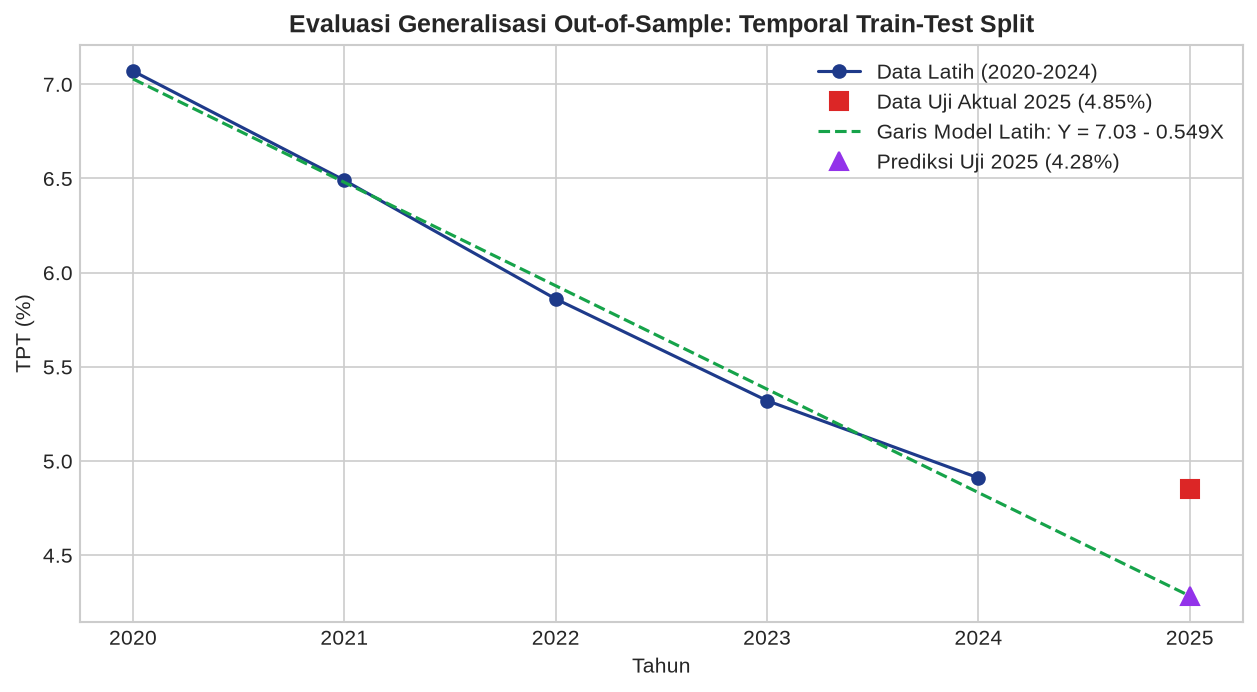

In [4]:
plt.figure(figsize=(10, 5))
train_years = data.years[:-1]
test_year = data.years[-1:]
train_y = data.y[:-1]
test_y = data.y[-1:]

x_plot = np.linspace(0, 5, 100)
y_plot = model_split.intercept_ + model_split.slope_ * x_plot

plt.plot(train_years, train_y, 'o-', color='#1e3a8a', label='Data Latih (2020-2024)')
plt.plot(test_year, test_y, 's', color='#dc2626', markersize=9, label='Data Uji Aktual 2025 (4.85%)')
plt.plot(2020 + x_plot, y_plot, '--', color='#16a34a', label=f"Garis Model Latih: Y = {model_split.intercept_:.2f} - {abs(model_split.slope_):.3f}X")
plt.plot(2025, split_res.test_predicted, '^', color='#9333ea', markersize=9, label=f"Prediksi Uji 2025 ({split_res.test_predicted:.2f}%)")

plt.title("Evaluasi Generalisasi Out-of-Sample: Temporal Train-Test Split", fontweight='bold')
plt.xlabel("Tahun")
plt.ylabel("TPT (%)")
plt.legend()
plt.show()

## Kesimpulan Tahap 3
Model menunjukkan kemampuan generalisasi yang sangat tinggi pada data uji riil tahun 2025 (akurasi $88{,}31\%$) serta MAPE validasi silang sebesar $4{,}67\%$ ($< 10\%$, kategori *highly accurate*).